# Time-Varying Parameter VARs with Stochastic Volatility

*Which time variation does the data want? Chan & Eisenstat (2018) with Peruvian data*

This tutorial uses the `TimeVaryingVAR` class of **MacroPy**, a port of the replication code of
**Chan & Eisenstat (2018, JAE)**, *"Bayesian model comparison for time-varying parameter VARs with
stochastic volatility"*. One class estimates the whole family, written in structural form with a
unit lower-triangular $A_t$:

\begin{align*}
A_t\, y_t &= \mu_t + B_{1t}\, y_{t-1} + \dots + B_{pt}\, y_{t-p} + \varepsilon_t,
\qquad \varepsilon_t \sim \mathcal{N}(0, \Sigma_t), \quad \Sigma_t = \mathrm{diag}\big(e^{h_{1t}}, \dots, e^{h_{nt}}\big) \\
\theta_t &= \theta_{t-1} + \eta_t, \qquad \eta_t \sim \mathcal{N}\big(0, \mathrm{diag}(\sigma^2_\theta)\big)
\quad \text{(whichever coefficients drift)} \\
h_t &= h_{t-1} + \zeta_t, \qquad \zeta_t \sim \mathcal{N}\big(0, \mathrm{diag}(\sigma^2_h)\big)
\quad \text{(stochastic volatility)}
\end{align*}

| model | time-varying | constant | variances |
|:-|:-|:-|:-|
| `C` | nothing | $\mu, B, A$ | constant |
| `C-SV` | nothing | $\mu, B, A$ | SV |
| `TVP` | $\mu_t, B_t, A_t$ | nothing | constant |
| `TVP-SV` | $\mu_t, B_t, A_t$ | nothing | SV |
| `TVP-R1-SV` | $A_t$ | $\mu, B$ | SV |
| `TVP-R2-SV` | $\mu_t, B_t$ | $A$ | SV |
| `TVP-R3-SV` | $\mu_t$ | $B, A$ | SV |

The reduced-form covariance is $\Omega_t = A_t^{-1}\Sigma_t A_t^{-1\prime}$, so $A_t^{-1}\Sigma_t^{1/2}$ is
its Cholesky factor: impulse responses, FEVD and historical decompositions use that recursive
identification **date by date**.

**Computation.** The states are drawn jointly over all dates by the precision-based sampler
(the $Tk \times Tk$ precision is block tridiagonal and is factorised in LAPACK band storage), the
log-volatilities by the auxiliary mixture sampler of Kim, Shephard & Chib (1998). Model comparison
uses the paper's **marginal likelihood** and **DIC** on the likelihood with the states integrated
out. Those two are optional and are the expensive part: each method prints its estimated time.

## 1. Data

Sample: 2002-06-01 to 2025-12-01 (95 quarters)


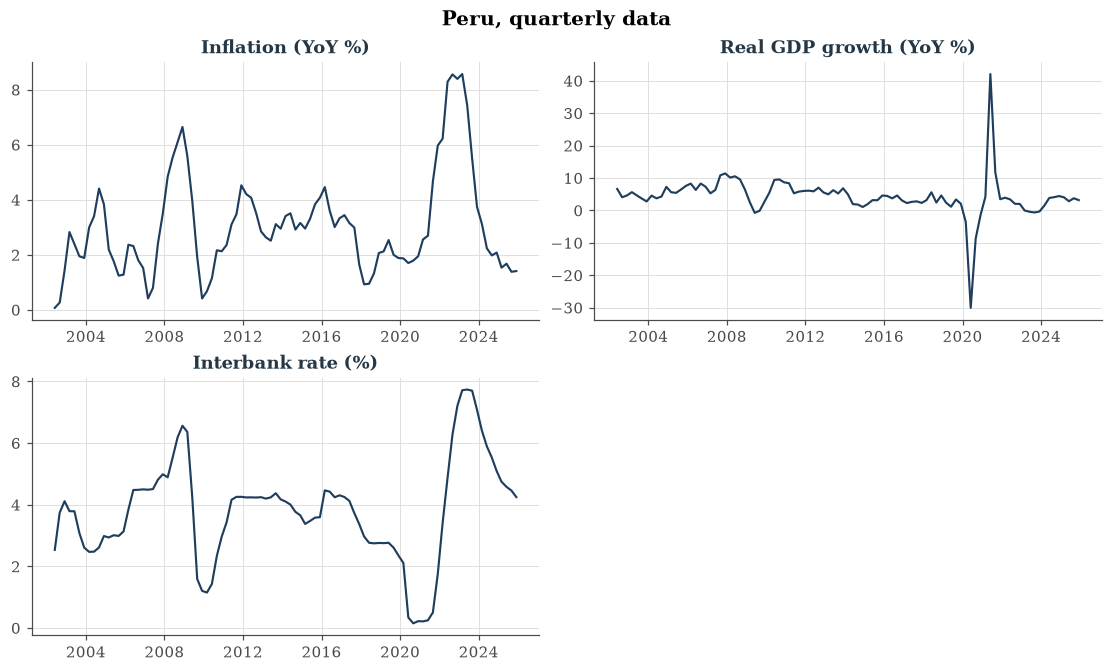

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from MacroPy import TimeVaryingVAR, compare_tvpvar, generate_series_plot

df = pd.read_csv('../datasets/Peru_Data.csv', index_col='date', parse_dates=True)
y = df[['g_ipc', 'g_pbi', 'int']].rename(columns={'g_ipc': 'pi', 'g_pbi': 'y', 'int': 'i'})
titles = ['Inflation (YoY %)', 'Real GDP growth (YoY %)', 'Interbank rate (%)']
print(f"Sample: {y.index[0].date()} to {y.index[-1].date()} ({len(y)} quarters)")
generate_series_plot(y, series_titles=titles, title='Peru, quarterly data')

The ordering $(\pi_t, y_t, i_t)$ is the recursive identification of Primiceri (2005) and Chan &
Eisenstat (2018): the interbank rate reacts within the quarter to inflation and activity, and the
**monetary policy shock** is the last one. The pandemic quarters (GDP falls 30 % in 2020Q2 and
rebounds 42 % a year later) are kept in the sample: stochastic volatility is meant to absorb them.

## 2. The benchmark: TVP-SV

`lags=2` with `presample=4`: the first four quarters are initial conditions for every model and
lag length, so every specification is estimated on the same sample and the marginal likelihoods are
comparable. As in `BayesianVAR`, `post_draws` counts all sweeps and `burnin` is the fraction
discarded (here 25,000 sweeps and 20,000 retained, the paper's choice). The priors are the paper's
(`TVP_PRIOR_DEFAULTS`); they are **scale dependent**, with prior-mean standard deviations of the
coefficient innovations of 0.01 (lags and $A_t$) and 0.1 (intercepts), in the units of the data.

In [2]:
model = TimeVaryingVAR(y, model='TVP-SV', lags=2, presample=4,
                       post_draws=25000, burnin=0.2, hor=21, fhor=8, seed=1)
model.model_summary()
draws = model.sample_posterior()


**MacroPy: A Toolbox for Bayesian Macroeconometric Analysis in Python**
Developed by [Renato Vassallo](https://www.linkedin.com/in/renatovassallo) - Institute for Economic Analysis (IAE-CSIC)
Version 0.2.0

---

**Model Specifications**
- **Model Type**: TVP-SV, Time-varying B_t and A_t, stochastic volatility (Chan & Eisenstat, 2018)
- **Endogenous Variables**: pi, y, i (recursive ordering)
- **Number of Lags (p)**: 2
- **Sample Period**: 2003-06-01 to 2025-12-01 (91 observations, 4 presample)
- **Time-varying States per Period**: 24
- **Constant Coefficients**: 0

---

**Bayesian Estimation Settings**
- **Posterior Simulation**: Gibbs sampling (precision-based states, auxiliary mixture SV)
- **Coefficient Priors**: N(0, 10) for constant coefficients and initial states
- **State Innovations**: IG prior means of sd 0.01 (lags, A_t) and 0.1 (intercepts), df 5
- **Variances**: random-walk log-volatilities, IG prior mean 0.01 (df 5)
- **Total Draws**: 25000
- **Burn-in**: 5000 (20%)

---

**Impulse Response Details**
- **IRF Horizon**: 21
- **Identification**: recursive, A_t^(-1) Sigma_t^(1/2), date by date

---

**Model Equations**

$$

\begin{align*}
A_t\, y_t &= \mu_t + \sum_{j=1}^{p} B_{j,t}\, y_{t-j} + \varepsilon_t, \qquad
\varepsilon_t \sim \mathcal{N}(0, \Sigma_t) \\
\Sigma_t &= \mathrm{diag}\big(e^{h_{1t}},\dots,e^{h_{nt}}\big), \qquad h_t = h_{t-1} + \zeta_t, \quad \zeta_t \sim \mathcal{N}(0, \mathrm{diag}(\sigma^2_h))\\ \theta_t &= \theta_{t-1} + \eta_t, \quad \eta_t \sim \mathcal{N}(0, \mathrm{diag}(\sigma^2_\theta)) \quad \text{(time-varying block)}
\end{align*}

$$


TVP-SV: 25000 sweeps (20000 retained), 1000 state paths stored (thin=20), about 27.0 MB.


Sampling Posterior: 100%|██████████| 25000/25000 [00:12<00:00, 2083.24it/s]


`sample_posterior` stores the draws in two layers. The hyperparameters (innovation variances,
initial states) are kept at every retained sweep, since the marginal likelihood and the DIC need
them. The state paths are $T \times k$ per draw, so they are thinned to at most 1,000 (pass `thin`
to change it). That is what the notice above reports.

### Stochastic volatility

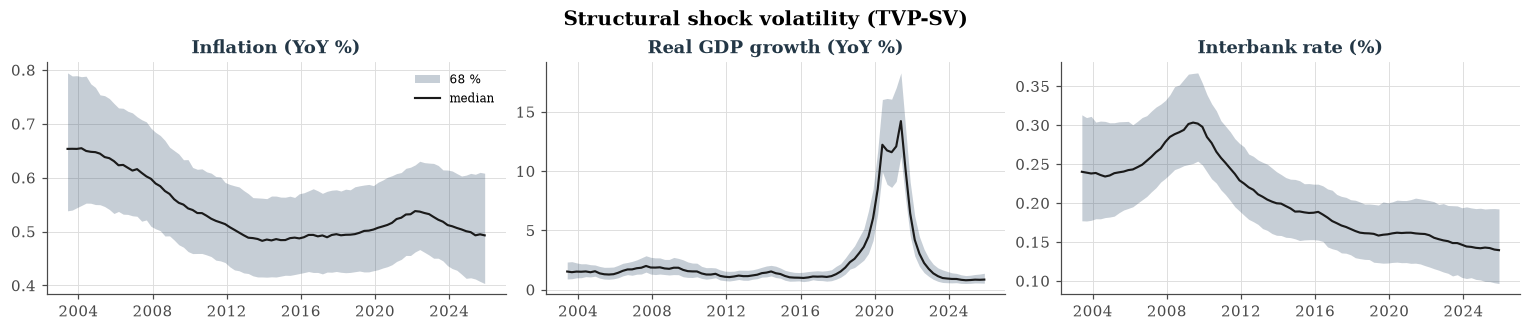

In [3]:
model.plot_volatility(series_titles=titles)

The standard deviation of the GDP-growth shock jumps from about 1.5 to more than 12 percentage
points in 2020-21 and is back to its pre-pandemic level by 2023: the **volatility**, not the
coefficients, absorbs the pandemic. Interbank-rate shocks were most volatile around the 2008-09
easing and have trended down since; inflation shocks became calmer after the mid-2000s.

### How much do the coefficients drift?

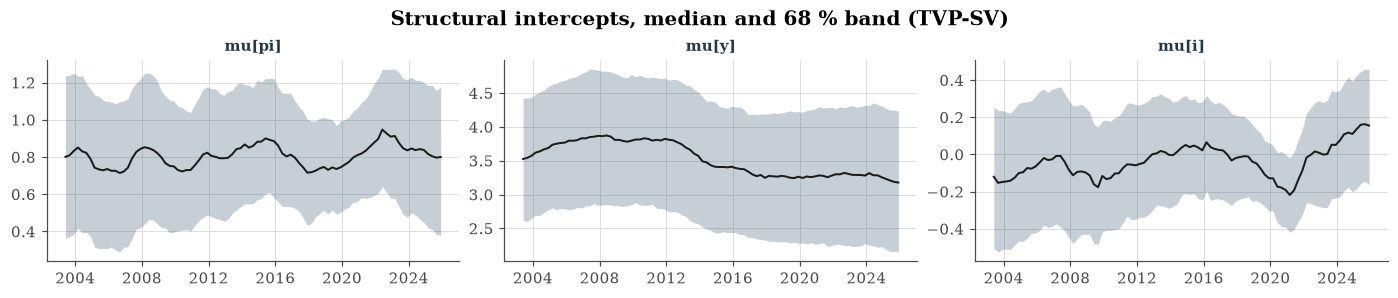

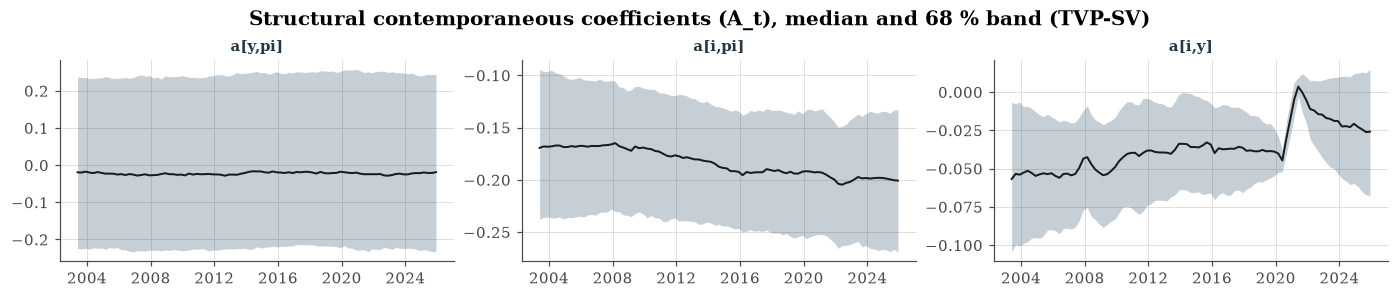

In [4]:
model.plot_coefficients(block='intercept')
model.plot_coefficients(block='impact')

The prior lets the coefficients drift slowly (a prior-mean standard deviation of 0.01 per quarter
for lags and $A_t$), and the intercepts move little. The exception is $a_{[i,y]}$, the element of
$A_t$ linking the interbank rate to GDP growth within the quarter. In the structural equation
$i_t + a_{[i,\pi]}\pi_t + a_{[i,y]} y_t = \dots$ the rate reacts to an activity surprise with
$-a_{[i,y]} \approx 0.04$ before 2020; in 2020-21 the reaction disappears, when the policy rate sat at
its 0.25 % floor while GDP collapsed and rebounded.

## 3. Impulse responses that change over time

At each date $t$ the response is computed with the parameters held at their date-$t$ values along
the horizon (Primiceri, 2005). `compute_irfs` stores the posterior median and the credible bands for
**every** date (they feed the 3D and over-time figures) and the full posterior draws only for the
dates you ask for, which keeps memory bounded. With `irf_1std=1` (the default) the shock is one
standard deviation **at that date**, so its size moves with the volatility; `irf_1std=0` gives unit
shocks.

Computing IRFs: 100%|██████████| 91/91 [00:00<00:00, 173.05it/s]

{'2008Q4': (1000, 21, 3, 3), '2016Q4': (1000, 21, 3, 3), '2023Q2': (1000, 21, 3, 3)}


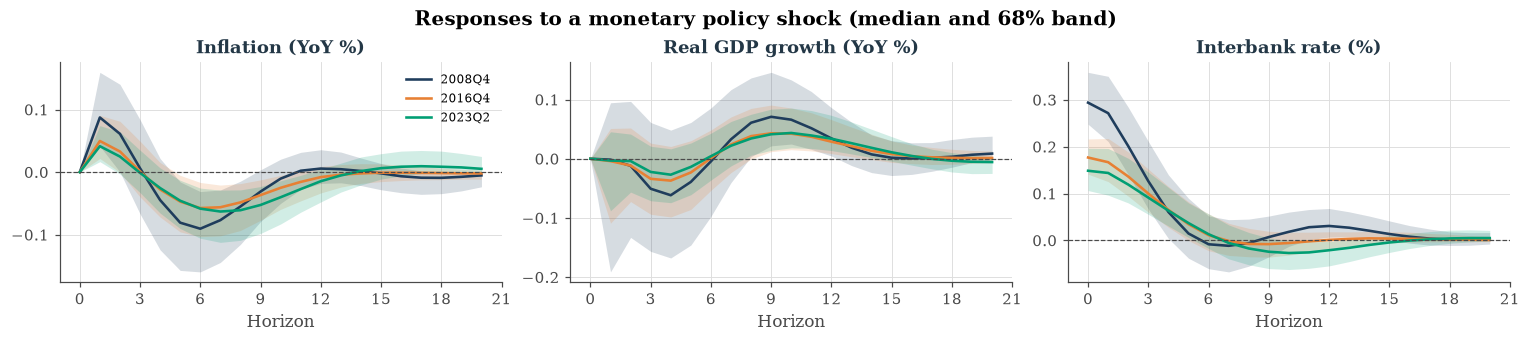

In [5]:
irf = model.compute_irfs(dates=['2008Q4', '2016Q4', '2023Q2'], cred_interval=[0.68, 0.90])
print({k: v.shape for k, v in irf['draws'].items()})
model.plot_irfs(shock='i', cred=0.68, series_titles=titles,
                title='Responses to a monetary policy shock (median and 68% band)')

A one-standard-deviation policy shock raises the interbank rate by about 0.3 points in 2008Q4 and
0.15 in 2023Q2: the shocks became smaller as their volatility fell (`irf_1std=0` would separate size
from transmission). Inflation rises slightly in the first two quarters, the *price puzzle* common in
recursive VARs, and falls by 0.06 to 0.09 points after six quarters; GDP growth dips during the first
year and overshoots later. The bands of the three dates overlap: the transmission itself is fairly
stable over time.

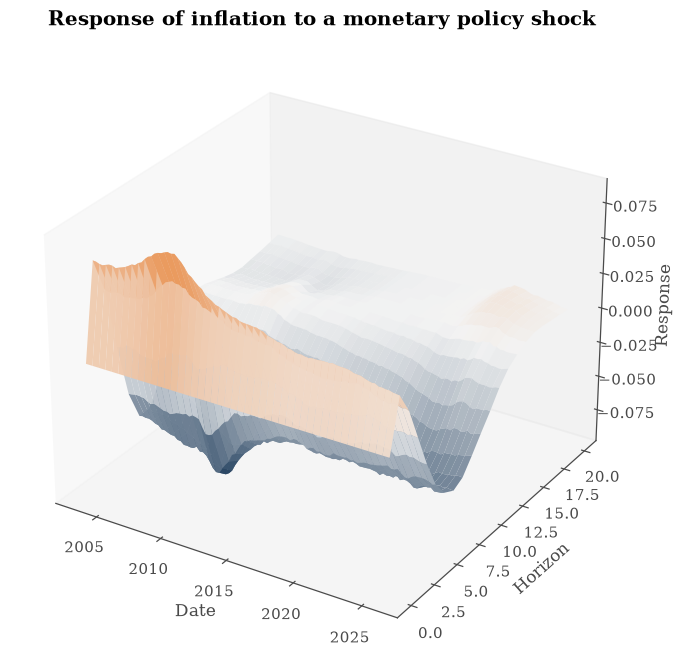

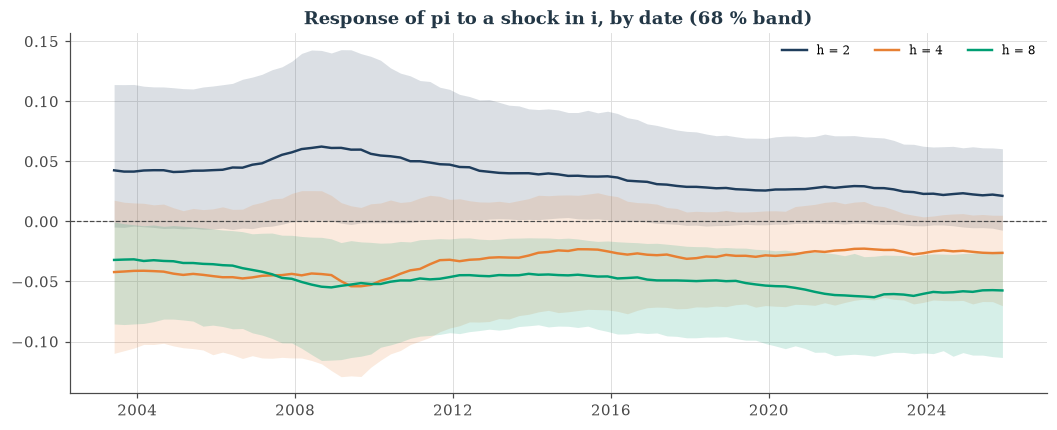

In [6]:
from MacroPy import plot_irf_over_time

model.plot_irf_surface(response='pi', shock='i',
                       title='Response of inflation to a monetary policy shock')
plot_irf_over_time(model, response='pi', shock='i', horizons=(2, 4, 8), cred=0.68)

The surface and its cuts tell the same story. The shape of the inflation response hardly changes;
its early positive hump shrinks after 2010, and at eight quarters the response stays between
$-0.03$ and $-0.06$, with a 68 % band below zero for most of the sample.

## 4. Forecast error variance decomposition over time

At date $t$ the share of shock $j$ in the $h$-step forecast error variance of variable $i$ uses the
date-$t$ responses: $\sum_{l<h}\theta_{l,t}[i,j]^2 / \sum_{l<h}\sum_m \theta_{l,t}[i,m]^2$.

Computing FEVD: 100%|██████████| 91/91 [00:00<00:00, 280.41it/s]


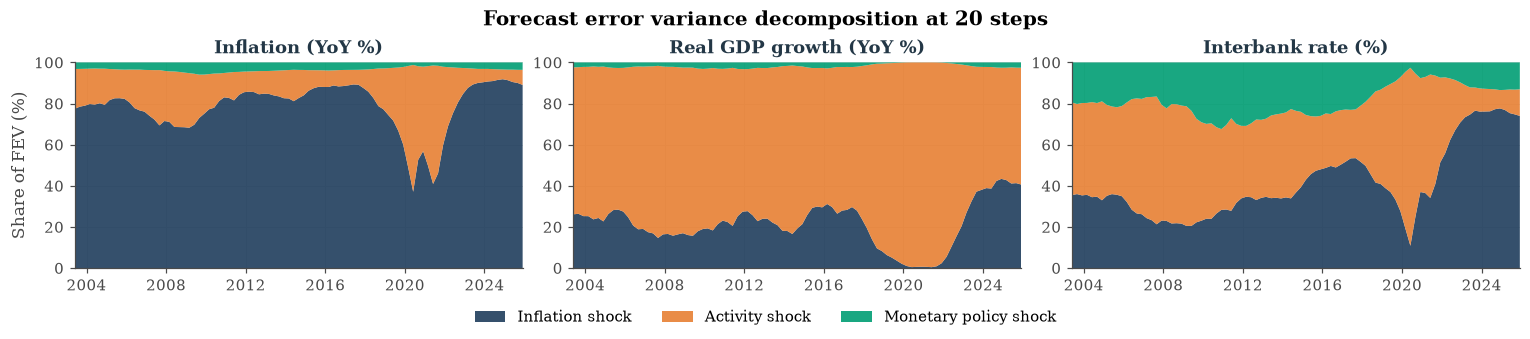

In [7]:
fevd = model.compute_fevd()
model.plot_fevd(horizon=20, series_titles=titles,
                shock_titles=['Inflation shock', 'Activity shock', 'Monetary policy shock'])

At five years (20 quarters), monetary policy shocks explain between a few percent and about a third
of the interbank-rate variance and very little of inflation and growth: most movements of the policy
rate are systematic responses to inflation and activity shocks. The weight of inflation shocks in
the interbank rate has risen since the mid-2010s and dominates after the 2022-23 inflation episode.
During the pandemic, activity shocks dominate growth and the interbank rate and account for about
60 % of the inflation variance. The shares change little between two and five years, so the reading
does not hinge on the horizon chosen.

## 5. Historical decomposition

For every stored draw the companion recursion runs with the date-$t$ reduced form; the baseline
propagates the initial conditions and the (time-varying) intercepts, and each shock's contribution
starts at zero. The identity `baseline + contributions = data` holds draw by draw.

Computing HD: 100%|██████████| 91/91 [00:00<00:00, 1935.43it/s]


max |baseline + contributions - data| = 8.5e-14


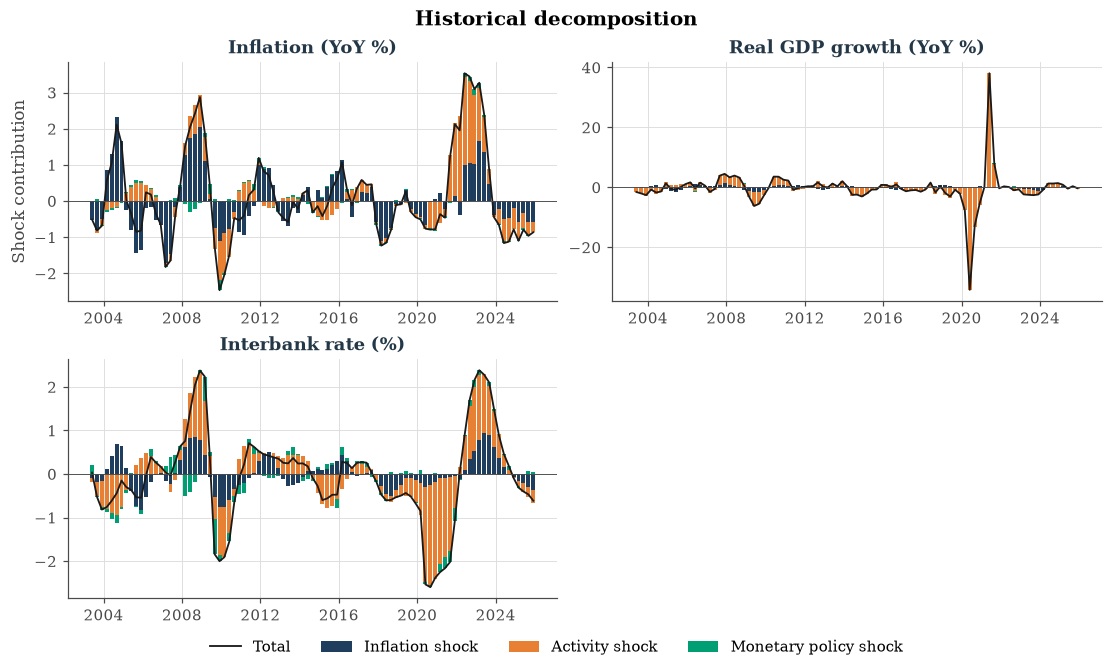

In [8]:
hd = model.compute_hd(plot_hd=True, series_titles=titles,
                      shock_titles=['Inflation shock', 'Activity shock', 'Monetary policy shock'])
print('max |baseline + contributions - data| =',
      f"{np.abs(hd['baseline'] + hd['shock'].sum(axis=1) - model.yy).max():.1e}")

The 2022-23 inflation surge is attributed to inflation shocks and, for a larger part, to activity
shocks (the post-pandemic demand recovery); the 2022-23 tightening of the interbank rate is mostly
the systematic reaction to those same shocks, with small policy-shock contributions. The collapse
and rebound of GDP in 2020-21 are activity shocks, as expected.

## 6. Forecasts and fan charts

`forecast` simulates the predictive density recursively: each stored draw is iterated forward from
the last observation, feeding its own forecasts back as lags. With `drift=True` (the model's
predictive density) the coefficients and the log-volatilities keep following their random walks over
the horizon; `drift=False` freezes them at their last values, so only future shocks spread the paths.
`reps` adds paths per stored draw for smoother bands.

date  mean  median   q05   q16   q84   q95
variable horizon                                                 
pi       1       2026-03-01  1.51    1.51  0.57  0.94  2.08  2.46
         2       2026-06-01  1.68    1.67  0.09  0.74  2.64  3.32
         3       2026-09-01  1.88    1.86 -0.24  0.61  3.17  4.14
         4       2026-12-01  2.11    2.09 -0.52  0.54  3.66  4.89
         5       2027-03-01  2.31    2.26 -0.78  0.42  4.12  5.58
         6       2027-06-01  2.49    2.43 -0.94  0.47  4.55  6.23
         7       2027-09-01  2.61    2.51 -1.12  0.40  4.82  6.62
         8       2027-12-01  2.69    2.59 -1.23  0.32  5.03  7.05
i        1       2026-03-01  4.12    4.12  3.68  3.87  4.38  4.55
         2       2026-06-01  4.06    4.06  3.17  3.54  4.58  4.96
         3       2026-09-01  4.08    4.06  2.70  3.26  4.92  5.57
         4       2026-12-01  4.16    4.14  2.24  3.00  5.32  6.24
         5       2027-03-01  4.29    4.22  1.81  2.81  5.81  6.90
         6       2027-06-01  4.43    4.33  1.49  2.63  6.23  7.67
         7       2027-09-01  4.57    4.45  1.21  2.51  6.61  8.34
         8       2027-12-01  4.69    4.54  0.94  2.39  7.03  8.98

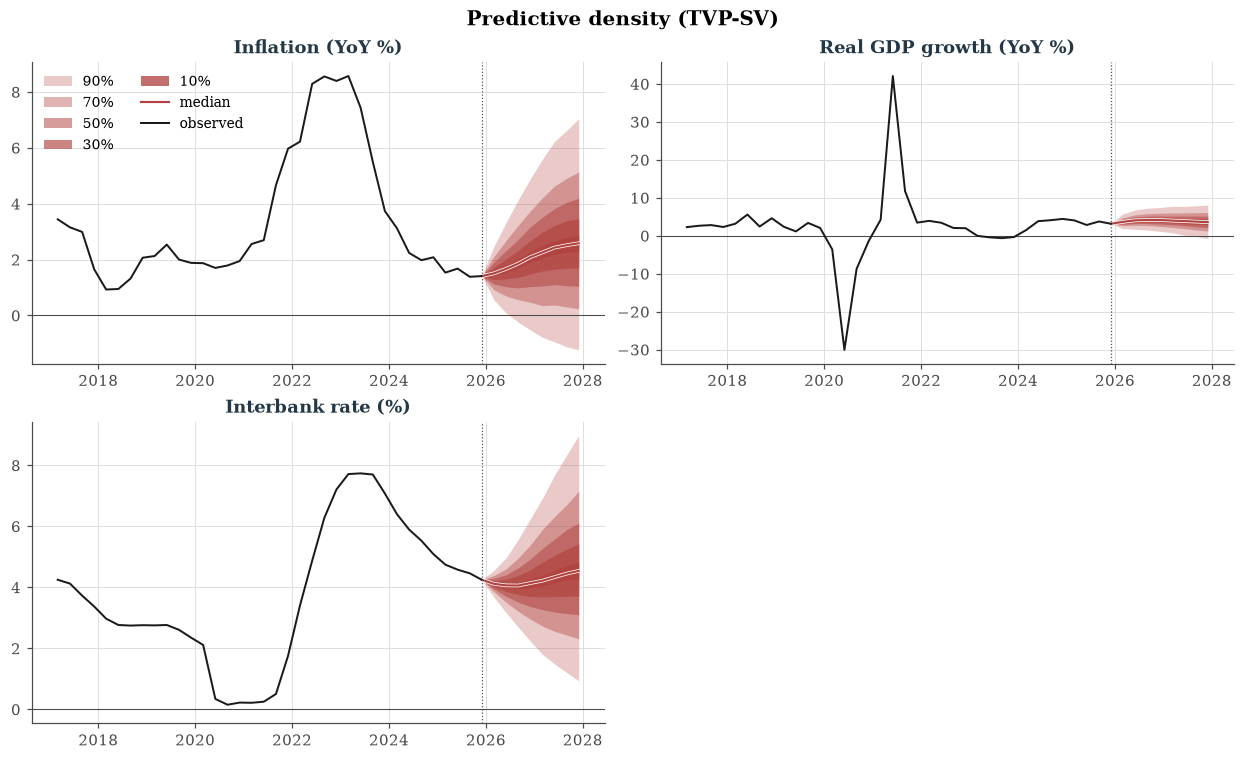

In [9]:
fc = model.forecast(fhor=8, reps=5)
model.plot_fan_chart(history_from='2017-01-01', series_titles=titles, hline=0)
model.forecast_frame(fhor=8, quantiles=(0.05, 0.16, 0.84, 0.95), reps=5).round(2).loc[['pi', 'i']]

In [10]:
def width90(draws):
    q = np.percentile(draws, [5, 95], axis=0)
    return pd.DataFrame(q[1] - q[0], columns=model.names, index=range(1, draws.shape[1] + 1))

fixed = model.forecast(fhor=8, reps=5, drift=False)['forecast_draws']
drifting = model.forecast(fhor=8, reps=5, drift=True)['forecast_draws']
pd.concat({'drift=True': width90(drifting), 'drift=False': width90(fixed)}, axis=1).round(2).iloc[[0, 3, 7]]

drift=True             drift=False            
          pi     y     i          pi     y     i
1       1.90  3.90  0.87        1.88  3.79  0.77
4       5.41  6.26  4.00        4.73  5.34  3.18
8       8.28  8.80  8.04        6.16  6.71  5.69

Inflation (1.4 % in 2025Q4) is projected to return towards the target range, with a median of
2.6 % two years ahead and a wide 90 % interval (about $-1.2$ to $7$ %). Parameter drift matters for the
width of the fan: letting the coefficients and volatilities keep moving over the horizon widens the
eight-quarter 90 % bands by about a third (inflation: 8.3 against 6.2 points).

## 7. Which time variation does the data want?

The paper's answer is a **marginal likelihood** (higher is better) and a **DIC** (lower is better)
for each specification, both on the likelihood with the states integrated out:

* the marginal likelihood is estimated by importance sampling over the hyperparameters, with a
  proposal fitted to the posterior draws; for each draw the coefficients are integrated out
  analytically and the log-volatilities by a second importance sampler centred at the mode of
  $p(h \mid y)$ (found by EM);
* the DIC averages the same integrated likelihood over the posterior.

**Cost.** Both are optional. Each method times its first evaluations and prints the expected run
time and memory; `n_jobs=-1` spreads the work over all cores. The models with time-varying
coefficients **and** SV are the expensive ones (an EM search and a dense $Tn \times Tn$ Hessian per
evaluation). With this sample the whole comparison takes a few minutes on a laptop.

**Caveat.** The numerical standard error measures importance-sampling noise *given* the chain the
proposal was fitted to. In TVP models several coefficients can compete to absorb the same drift and
the posterior can be multimodal; a short chain stuck in one mode yields a biased estimate with a
small NSE. Use long chains (as here) and, for the final comparison, check two or three seeds.

In [11]:
RUN_ML, RUN_DIC = True, True          # set to False to skip the expensive part

specs = ['C', 'C-SV', 'TVP', 'TVP-SV', 'TVP-R1-SV', 'TVP-R2-SV', 'TVP-R3-SV']
fitted = {}
for spec in specs:
    m = model if spec == 'TVP-SV' else TimeVaryingVAR(
        y, model=spec, lags=2, presample=4, post_draws=25000, burnin=0.2, seed=1, progress=False)
    if m.draws is None:
        m.sample_posterior()
    m.progress = True                 # show the cost notices
    if RUN_ML:
        m.log_marginal_likelihood(n_draws=2000, n_jobs=-1)
    if RUN_DIC:
        m.dic(n_jobs=-1)
    m.progress = False
    fitted[spec] = m

Marginal likelihood (C): 2000 evaluations at ~0.000 s each; about 0 s with 10 worker(s).


Marginal likelihood: 100%|██████████| 79/79 [00:01<00:00, 48.14it/s]


DIC (C): 1000 evaluations at ~0.000 s each; about 0 s with 10 worker(s).


Computing DIC: 100%|██████████| 39/39 [00:00<00:00, 19926.65it/s]


Marginal likelihood (C-SV): 2000 evaluations at ~0.000 s each; about 0 s with 10 worker(s).


...

Computing DIC: 100%|██████████| 39/39 [00:01<00:00, 22.00it/s]


Marginal likelihood (TVP-R3-SV): 2000 evaluations at ~0.008 s each; about 2 s with 10 worker(s), ~2 MB of dense matrices per worker.


Marginal likelihood: 100%|██████████| 79/79 [00:02<00:00, 35.43it/s]


DIC (TVP-R3-SV): 1000 evaluations at ~0.009 s each; about 1 s with 10 worker(s), ~2 MB of dense matrices per worker.


Computing DIC: 100%|██████████| 39/39 [00:00<00:00, 53.57it/s]


In [12]:
table = compare_tvpvar(fitted)
table.round(2)

,logml,logml_nse,dic,dic_nse,pD,rank_logml,rank_dic
model,,,,,,,
C,-519.95,0.01,859.65,0.58,24.59,6,6
C-SV,-428.03,0.08,670.74,0.79,34.24,3,2
TVP,-525.43,0.19,887.56,1.20,21.29,7,7
TVP-SV,-420.90,0.12,699.19,1.07,29.22,2,4
TVP-R1-SV,-420.57,0.14,669.45,0.81,32.80,1,1
TVP-R2-SV,-429.15,0.22,710.80,2.00,34.97,4,5
TVP-R3-SV,-431.90,0.11,683.93,1.85,33.36,5,3


Three readings.

1. **Stochastic volatility is what the data want most.** Adding SV raises the log marginal
   likelihood by about 92 points to the constant model (C to C-SV) and by 105 to the TVP model: a
   constant variance cannot accommodate the pandemic quarters.
2. **Given SV, the time variation that pays is in $A_t$.** TVP-R1-SV beats C-SV by about 7.5 log
   points and the fully time-varying TVP-SV is as good as R1, while drifting lag coefficients (R2)
   or intercepts (R3) lose against the constant-coefficient C-SV.
3. **The DIC agrees on the top** (R1, then C-SV) and on the importance of SV, but ranks TVP-SV only
   fourth. The two criteria penalise flexibility differently (the marginal likelihood through the
   prior predictive, the DIC through $p_D$), and a handful of extreme quarters can separate them.

### Is the gain from a drifting $A_t$ a pandemic artifact?

The same comparison on the pre-pandemic sample (2002-2019), for the four models that matter:

In [13]:
pre = y.loc[:'2019-12-01']
fitted_pre = {}
for spec in ['C-SV', 'TVP-SV', 'TVP-R1-SV', 'TVP-R3-SV']:
    m = TimeVaryingVAR(pre, model=spec, lags=2, presample=4, post_draws=25000, burnin=0.2,
                       seed=1, progress=False)
    m.sample_posterior()
    if RUN_ML:
        m.log_marginal_likelihood(n_draws=2000, n_jobs=-1)
    fitted_pre[spec] = m
compare_tvpvar(fitted_pre).round(2)

,logml,logml_nse,rank_logml
model,,,
C-SV,-280.37,0.03,3
TVP-SV,-282.66,0.11,4
TVP-R1-SV,-280.14,0.13,1
TVP-R3-SV,-280.23,0.11,2


Before 2020 there is **no evidence of drift** in any coefficient block once volatility can change:
C-SV, TVP-R1-SV and TVP-R3-SV tie within a fraction of a log point, and the fully time-varying model
loses about two points. The full-sample advantage of a drifting $A_t$ comes from the pandemic, when
the within-quarter link between activity and the policy rate broke (section 2). The robust message
is **time-varying volatility first**; coefficient drift is a second-order and sample-dependent
feature. On Chan & Eisenstat's US data (1955-2014, $p = 2$) this port finds the same pattern: C-SV,
TVP-R1-SV and TVP-R3-SV within about one log point, every constant-variance model far behind.

## 8. Notes

* **Prior sensitivity.** The state-innovation priors drive how much drift the TVP models allow.
  Try `prior_params={'state_sd': 0.02}` and compare the marginal likelihoods, which penalise the
  extra flexibility automatically.
* **Lag length.** Keep `presample=4` and change `lags` between 1 and 4: the samples stay identical
  and the marginal likelihoods remain comparable.
* **Units.** The default priors assume data in percent; rescaling the data changes their meaning.

## References

- Chan, J.C.C. and Eisenstat, E. (2018). Bayesian model comparison for time-varying parameter VARs with stochastic volatility. *Journal of Applied Econometrics* 33(4), 509-532.
- Chan, J.C.C. and Jeliazkov, I. (2009). Efficient simulation and integrated likelihood estimation in state space models. *International Journal of Mathematical Modelling and Numerical Optimisation* 1(1/2), 101-120.
- Kim, S., Shephard, N. and Chib, S. (1998). Stochastic volatility: likelihood inference and comparison with ARCH models. *Review of Economic Studies* 65(3), 361-393.
- Primiceri, G.E. (2005). Time varying structural vector autoregressions and monetary policy. *Review of Economic Studies* 72(3), 821-852.